# Clasificación supervisada para una campaña de depósitos a plazo

**Curso:** Inteligencia Artificial para Negocios I
**Docente:** Hugo Alatrista Salas
**Estudiante:** Josué Benjamin Puma Jiménez


Este notebook resuelve un problema de clasificación binaria aplicado a una campaña de marketing
telefónico de un banco.

In [1]:

import warnings
from pathlib import Path


warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (7, 4.5)


RUTA_LOCAL = Path('bank.csv')
URL_DATOS = 'https://raw.githubusercontent.com/redneurocom/PC1-1FDA0005/main/bank.csv'
bank = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL_DATOS, sep=';')

print('Observaciones y variables:', bank.shape)
bank.head()

Observaciones y variables: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


## 1. Definición del problema predictivo de negocio

Contexto de negocio. Un banco ejecuta campañas de marketing telefónico para colocar depósitos a
plazo fijo. Cada llamada consume tiempo de un agente, la capacidad del centro de contacto es
limitada y llamar a toda la base de clientes no es viable, así que la decisión que se quiere mejorar
es a qué clientes conviene llamar primero en la próxima campaña.

Variable objetivo. `y`, que indica si el cliente contrató el depósito a plazo después del contacto
(`yes`) o no lo contrató (`no`). Se codifica como 1 y 0, con la contratación como clase positiva.

Tipo de problema. Clasificación binaria, porque la variable objetivo tiene dos categorías
mutuamente excluyentes.

Utilidad para la toma de decisiones. El modelo estima la probabilidad de contratación de cada
cliente, lo que permite ordenar la base y concentrar la capacidad de llamadas en los clientes de
mayor propensión en lugar de recorrer la lista sin criterio.

Conjunto de datos. Bank Marketing (bank.csv), con 4521 observaciones y 17 variables separadas por
punto y coma. Incluye atributos del cliente (edad, ocupación, estado civil, educación, saldo
promedio, hipoteca, préstamo personal, mora), del contacto (canal, día y mes de la última llamada,
duración, número de contactos de la campaña) y del historial (días desde el contacto anterior,
contactos previos y resultado de la campaña anterior).

In [2]:
# Revisión de variables: tipo, valores distintos, nulos y marcas de 'unknown'
resumen = pd.DataFrame({
    'tipo': bank.dtypes.astype(str),
    'valores_distintos': bank.nunique(),
    'nulos': bank.isna().sum(),
    'marcas_unknown': [(bank[c] == 'unknown').sum() if bank[c].dtype.kind not in 'ifu' else 0
                       for c in bank.columns]
})
print(resumen.to_string())

tasa_positiva = (bank['y'] == 'yes').mean()
print('\nDistribución de la variable objetivo y:')
print(bank['y'].value_counts().to_string())
print(f'Tasa de contratación: {tasa_positiva:.2%}')
print('Proporción de la clase mayoritaria (accuracy de la línea base trivial): '
      f'{1 - tasa_positiva:.2%}')

            tipo  valores_distintos  nulos  marcas_unknown
age        int64                 67      0               0
job          str                 12      0              38
marital      str                  3      0               0
education    str                  4      0             187
default      str                  2      0               0
balance    int64               2353      0               0
housing      str                  2      0               0
loan         str                  2      0               0
contact      str                  3      0            1324
day        int64                 31      0               0
month        str                 12      0               0
duration   int64                875      0               0
campaign   int64                 32      0               0
pdays      int64                292      0               0
previous   int64                 24      0               0
poutcome     str                  4      0            37

## 2. Preparación inicial de los datos

Se elimina `duration` porque registra cuánto duró la llamada, un dato que solo existe después del
contacto y que no está disponible cuando el banco decide a quién llamar; conservarla elevaría las
métricas de forma irreal. La marca `unknown` se mantiene como categoría propia, ya que en
`poutcome` identifica a los clientes sin campaña previa y reemplazarla por la moda inventaría un
historial inexistente. En `pdays` el código -1 indica ausencia de contacto anterior, así que se
separa en un indicador binario y en el conteo de días.

El conjunto no contiene identificadores directos de personas y no se agrega ninguno; solo se
conservan las variables con finalidad analítica para esta decisión. Conviene advertir que la
ocupación, la educación o el estado civil pueden funcionar como proxy de características sensibles,
de modo que la priorización debe revisarse por segmento y el resultado sirve para ordenar contactos,
nunca para negar un producto.

La partición es estratificada, con 75 % de entrenamiento y 25 % de prueba, para que la clase
minoritaria conserve su proporción. La imputación, el escalado y la codificación one-hot se declaran
en un `ColumnTransformer` dentro del `Pipeline` de cada modelo, de manera que se ajustan solo con
los datos de entrenamiento. El escalado es necesario para los modelos que dependen de distancias y
márgenes; los ensambles de árboles no lo requieren, pero se mantiene el mismo preprocesador para
que la comparación sea justa.

In [3]:
datos = bank.copy()

# 1) Fuga de información: duration solo se conoce después de la llamada
COLUMNAS_FUGA = ['duration']

# 2) pdays usa -1 como ausencia de contacto previo: se separa el indicador del conteo de días
datos['contactado_antes'] = (datos['pdays'] != -1).astype(int)
datos['pdays'] = datos['pdays'].where(datos['pdays'] != -1, 0)

objetivo = 'y'
X = datos.drop(columns=[objetivo] + COLUMNAS_FUGA)
y = (datos[objetivo] == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

variables_numericas = X.select_dtypes(include='number').columns.tolist()
variables_categoricas = [c for c in X.columns if c not in variables_numericas]

preprocesador = ColumnTransformer([
    ('numericas', Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('escalado', StandardScaler())
    ]), variables_numericas),
    ('categoricas', Pipeline([
        ('imputacion', SimpleImputer(strategy='most_frequent')),
        ('codificacion', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), variables_categoricas)
])

print('Variables numéricas:', variables_numericas)
print('Variables categóricas:', variables_categoricas)
print(f'\nEntrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas')
print(f'Tasa de contratación en entrenamiento: {y_train.mean():.2%}')
print(f'Tasa de contratación en prueba: {y_test.mean():.2%}')
print('Columnas tras la codificación:',
      preprocesador.fit(X_train).transform(X_train).shape[1])

Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'contactado_antes']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Entrenamiento: 3390 filas | Prueba: 1131 filas
Tasa de contratación en entrenamiento: 11.53%
Tasa de contratación en prueba: 11.49%
Columnas tras la codificación: 51


## 3. Implementación de modelos supervisados

Cuatro modelos de familias distintas, más una línea base que fija la referencia mínima a superar.

| Modelo | Familia | Justificación de la selección |
|---|---|---|
| Línea base (clase mayoritaria) | Regla trivial | Con 88 % de clientes que no contratan, predecir siempre "no contrata" ya alcanza ese accuracy sin identificar a un solo cliente al que valga la pena llamar. Sirve para dimensionar la mejora real de los demás modelos. |
| KNN | Basado en instancias y distancias | Clasifica por mayoría entre los k vecinos más cercanos, sin suponer ninguna forma de frontera. Aporta un contraste no paramétrico y requiere el escalado del pipeline, porque una variable de gran magnitud como `balance` dominaría la distancia. |
| SVM con kernel RBF | Margen máximo con kernel | Busca el hiperplano que maximiza el margen y, con el kernel RBF, admite fronteras no lineales y regiones locales, pertinente porque la propensión a contratar combina edad, saldo e historial de campañas de forma no lineal. |
| Random Forest | Ensamble por bagging | Promedia árboles entrenados sobre muestras y subconjuntos aleatorios de variables, lo que reduce la varianza del modelo. Maneja relaciones no lineales sin escalado y permite leer la importancia de las variables. |
| LightGBM | Ensamble por boosting | Corrige de forma incremental los errores de los árboles anteriores, lo que reduce el sesgo, y suele ser el más competitivo en datos tabulares con variables numéricas y categóricas mezcladas. |

Los tres modelos que lo admiten usan `class_weight='balanced'`: con una tasa de contratación de
11,5 %, sin ponderación el modelo tiende a maximizar el accuracy prediciendo casi siempre la clase
mayoritaria. KNN no admite ese parámetro, lo que se toma en cuenta al leer su recall.

In [4]:
def metricas(nombre, modelo, X_eval=X_test, y_eval=y_test):
    # El modelo ya debe estar entrenado; devuelve las métricas de la clase positiva.
    prediccion = modelo.predict(X_eval)
    if hasattr(modelo, 'predict_proba'):
        puntaje = modelo.predict_proba(X_eval)[:, 1]
    else:
        puntaje = modelo.decision_function(X_eval)
    return {
        'modelo': nombre,
        'accuracy': accuracy_score(y_eval, prediccion),
        'precision': precision_score(y_eval, prediccion, zero_division=0),
        'recall': recall_score(y_eval, prediccion, zero_division=0),
        'f1': f1_score(y_eval, prediccion, zero_division=0),
        'roc_auc': roc_auc_score(y_eval, puntaje),
        'avg_precision': average_precision_score(y_eval, puntaje)
    }


def construir(estimador):
    return Pipeline([('preprocesamiento', preprocesador), ('modelo', estimador)])


modelos_iniciales = {
    'Línea base (clase mayoritaria)': construir(
        DummyClassifier(strategy='most_frequent')),
    'KNN (k=5)': construir(
        KNeighborsClassifier(n_neighbors=5)),
    'SVM RBF (C=1, gamma=scale)': construir(
        SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced',
            probability=True, random_state=RANDOM_STATE)),
    'Random Forest (300 árboles)': construir(
        RandomForestClassifier(n_estimators=300, class_weight='balanced',
                               random_state=RANDOM_STATE, n_jobs=-1)),
    'LightGBM (configuración inicial)': construir(
        LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight='balanced',
                       random_state=RANDOM_STATE, verbose=-1))
}

filas_iniciales = []
for nombre, modelo in modelos_iniciales.items():
    modelo.fit(X_train, y_train)
    filas_iniciales.append(metricas(nombre, modelo))

resultados_iniciales = pd.DataFrame(filas_iniciales).set_index('modelo').round(4)
print('Métricas iniciales sobre el conjunto de prueba (clase positiva = contrata)')
print(resultados_iniciales.to_string())

Métricas iniciales sobre el conjunto de prueba (clase positiva = contrata)
                                  accuracy  precision  recall      f1  roc_auc  avg_precision
modelo                                                                                       
Línea base (clase mayoritaria)      0.8851     0.0000  0.0000  0.0000   0.5000         0.1149
KNN (k=5)                           0.8789     0.3793  0.0846  0.1384   0.6182         0.1790
SVM RBF (C=1, gamma=scale)          0.7843     0.2720  0.5231  0.3579   0.7326         0.2837
Random Forest (300 árboles)         0.8576     0.3402  0.2538  0.2907   0.7242         0.3047
LightGBM (configuración inicial)    0.8426     0.3209  0.3308  0.3258   0.7028         0.2772


## 4. Optimización de hiperparámetros

Criterio de evaluación: F1 de la clase positiva, porque equilibra precision y recall. El recall por
sí solo mediría cuántos contratos se capturan sin considerar cuántas llamadas se gastan, y la
precision por sí sola llevaría a contactar a muy pocos clientes.

La búsqueda usa validación cruzada estratificada de cinco pliegues sobre el conjunto de
entrenamiento, de modo que el F1 reportado es un promedio y no el resultado de una sola partición.
El conjunto de prueba no participa en la búsqueda y queda reservado para la evaluación final. Se
aplica Grid Search donde el espacio de valores es pequeño y Randomized Search donde es mucho mayor
y recorrerlo completo resultaría innecesariamente costoso.

| Modelo | Técnica | Hiperparámetros evaluados |
|---|---|---|
| KNN | Grid Search | `n_neighbors`: 5, 11, 21, 31 y `weights`: uniform, distance. Las 8 combinaciones se probaron. |
| SVM RBF | Grid Search | `C`: 0,1 / 1 / 10 y `gamma`: scale / 0,01 / 0,1. Las 9 combinaciones se probaron. |
| Random Forest | Randomized Search | `n_estimators`: 200 / 300 / 500 / 800, `max_depth`: sin límite / 6 / 10 / 16, `min_samples_leaf`: 1 / 2 / 5 / 10, `max_features`: sqrt / log2 / 0,5. De 192 combinaciones posibles se muestrearon 10. |
| LightGBM | Randomized Search | `n_estimators`: 200 / 400 / 600, `learning_rate`: 0,01 / 0,05 / 0,1, `num_leaves`: 15 / 31 / 63, `min_child_samples`: 10 / 20 / 40, `subsample`: 0,8 / 1,0, `colsample_bytree`: 0,7 / 1,0. De 324 combinaciones posibles se muestrearon 10. |

In [5]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CRITERIO = 'f1'

busquedas = {}

# Grid Search para KNN: número de vecinos y ponderación por distancia
busquedas['KNN'] = GridSearchCV(
    construir(KNeighborsClassifier()),
    {'modelo__n_neighbors': [5, 11, 21, 31],
     'modelo__weights': ['uniform', 'distance']},
    scoring=CRITERIO, cv=validacion, n_jobs=-1
)

# Grid Search para SVM RBF: C y gamma
busquedas['SVM RBF'] = GridSearchCV(
    construir(SVC(kernel='rbf', class_weight='balanced', probability=True,
                  random_state=RANDOM_STATE)),
    {'modelo__C': [0.1, 1, 10],
     'modelo__gamma': ['scale', 0.01, 0.1]},
    scoring=CRITERIO, cv=validacion, n_jobs=-1
)

# Randomized Search para Random Forest
busquedas['Random Forest'] = RandomizedSearchCV(
    construir(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                     n_jobs=-1)),
    {'modelo__n_estimators': [200, 300, 500, 800],
     'modelo__max_depth': [None, 6, 10, 16],
     'modelo__min_samples_leaf': [1, 2, 5, 10],
     'modelo__max_features': ['sqrt', 'log2', 0.5]},
    n_iter=10, scoring=CRITERIO, cv=validacion, random_state=RANDOM_STATE, n_jobs=-1
)

# Randomized Search para LightGBM
busquedas['LightGBM'] = RandomizedSearchCV(
    construir(LGBMClassifier(class_weight='balanced', random_state=RANDOM_STATE, verbose=-1)),
    {'modelo__n_estimators': [200, 400, 600],
     'modelo__learning_rate': [0.01, 0.05, 0.1],
     'modelo__num_leaves': [15, 31, 63],
     'modelo__min_child_samples': [10, 20, 40],
     'modelo__subsample': [0.8, 1.0],
     'modelo__colsample_bytree': [0.7, 1.0]},
    n_iter=10, scoring=CRITERIO, cv=validacion, random_state=RANDOM_STATE, n_jobs=-1
)

optimizados, filas_busqueda = {}, []
for nombre, busqueda in busquedas.items():
    busqueda.fit(X_train, y_train)
    optimizados[nombre] = busqueda.best_estimator_
    filas_busqueda.append({
        'modelo': nombre,
        'tecnica': 'Grid Search' if isinstance(busqueda, GridSearchCV) else 'Randomized Search',
        'combinaciones': len(busqueda.cv_results_['params']),
        'f1_validacion_cruzada': busqueda.best_score_,
        'mejores_hiperparametros': {k.replace('modelo__', ''): v
                                    for k, v in busqueda.best_params_.items()}
    })

resumen_busqueda = pd.DataFrame(filas_busqueda).set_index('modelo')
for nombre, fila in resumen_busqueda.iterrows():
    print(f"{nombre}: {fila['tecnica']} sobre {fila['combinaciones']} combinaciones | "
          f"F1 en validación cruzada = {fila['f1_validacion_cruzada']:.4f}")
    print('   mejores hiperparámetros:', fila['mejores_hiperparametros'])

KNN: Grid Search sobre 8 combinaciones | F1 en validación cruzada = 0.2034
   mejores hiperparámetros: {'n_neighbors': 5, 'weights': 'distance'}
SVM RBF: Grid Search sobre 9 combinaciones | F1 en validación cruzada = 0.3539
   mejores hiperparámetros: {'C': 1, 'gamma': 'scale'}
Random Forest: Randomized Search sobre 10 combinaciones | F1 en validación cruzada = 0.3997
   mejores hiperparámetros: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
LightGBM: Randomized Search sobre 10 combinaciones | F1 en validación cruzada = 0.4010
   mejores hiperparámetros: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 400, 'min_child_samples': 10, 'learning_rate': 0.01, 'colsample_bytree': 0.7}


In [6]:
# Comparación entre el desempeño inicial y el optimizado, sobre el mismo conjunto de prueba
equivalencias = {
    'KNN': 'KNN (k=5)',
    'SVM RBF': 'SVM RBF (C=1, gamma=scale)',
    'Random Forest': 'Random Forest (300 árboles)',
    'LightGBM': 'LightGBM (configuración inicial)'
}

filas_comparacion = []
for nombre, modelo in optimizados.items():
    inicial = resultados_iniciales.loc[equivalencias[nombre]]
    final = metricas(nombre, modelo)
    filas_comparacion.append({
        'modelo': nombre,
        'f1_inicial': inicial['f1'],
        'f1_optimizado': final['f1'],
        'diferencia_f1': final['f1'] - inicial['f1'],
        'roc_auc_inicial': inicial['roc_auc'],
        'roc_auc_optimizado': final['roc_auc']
    })

comparacion_optimizacion = pd.DataFrame(filas_comparacion).set_index('modelo').round(4)
print('Desempeño inicial frente a desempeño optimizado (conjunto de prueba)')
print(comparacion_optimizacion.to_string())

Desempeño inicial frente a desempeño optimizado (conjunto de prueba)
               f1_inicial  f1_optimizado  diferencia_f1  roc_auc_inicial  roc_auc_optimizado
modelo                                                                                      
KNN                0.1384         0.1350        -0.0034           0.6182              0.6209
SVM RBF            0.3579         0.3579        -0.0000           0.7326              0.7326
Random Forest      0.2907         0.3599         0.0692           0.7242              0.7402
LightGBM           0.3258         0.3988         0.0730           0.7028              0.7325


## 5. Comparación de desempeño entre modelos

Los cuatro modelos optimizados se comparan sobre el mismo conjunto de prueba con accuracy,
precision, recall, F1, ROC-AUC y matriz de confusión. Se agrega la average precision, que resume la
curva de precision-recall y resulta más informativa que el ROC-AUC cuando la clase positiva es
escasa.

In [7]:
tabla_final = pd.DataFrame([metricas(nombre, modelo) for nombre, modelo in optimizados.items()])
linea_base = resultados_iniciales.loc[['Línea base (clase mayoritaria)']].reset_index()
tabla_final = pd.concat([linea_base, tabla_final], ignore_index=True).set_index('modelo').round(4)

print('Comparación final sobre el conjunto de prueba')
print(tabla_final.to_string())

mejor_nombre = tabla_final.drop(index='Línea base (clase mayoritaria)')['f1'].idxmax()
mejor_modelo = optimizados[mejor_nombre]
print(f'\nMejor modelo según el criterio F1: {mejor_nombre}')

Comparación final sobre el conjunto de prueba
                                accuracy  precision  recall      f1  roc_auc  avg_precision
modelo                                                                                     
Línea base (clase mayoritaria)    0.8851     0.0000  0.0000  0.0000   0.5000         0.1149
KNN                               0.8753     0.3333  0.0846  0.1350   0.6209         0.2098
SVM RBF                           0.7843     0.2720  0.5231  0.3579   0.7326         0.2837
Random Forest                     0.8081     0.2919  0.4692  0.3599   0.7402         0.3398
LightGBM                          0.8267     0.3316  0.5000  0.3988   0.7325         0.3305

Mejor modelo según el criterio F1: LightGBM


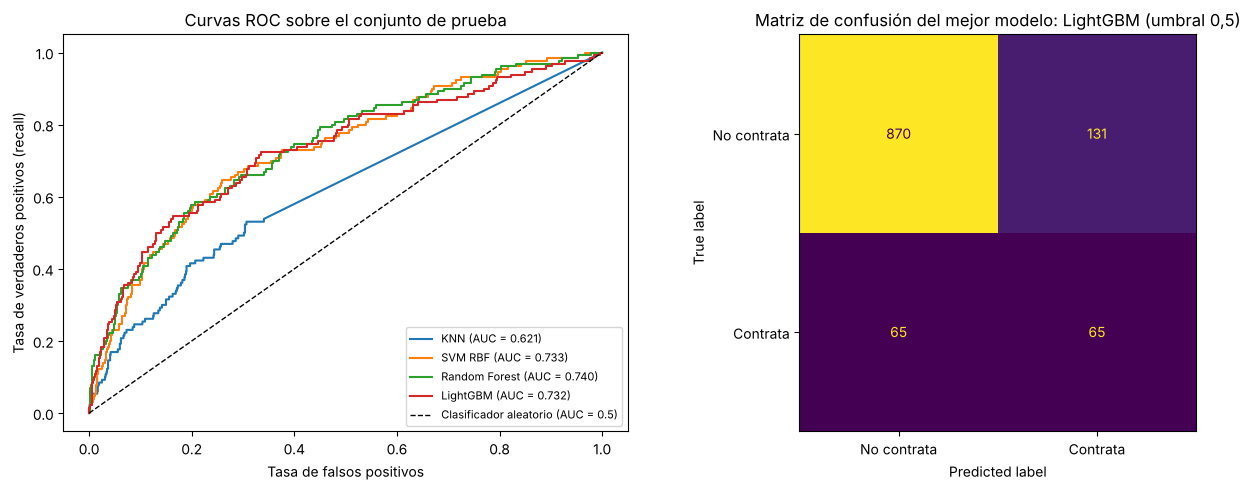

Reporte de clasificación del mejor modelo (LightGBM):
              precision    recall  f1-score   support

 No contrata       0.93      0.87      0.90      1001
    Contrata       0.33      0.50      0.40       130

    accuracy                           0.83      1131
   macro avg       0.63      0.68      0.65      1131
weighted avg       0.86      0.83      0.84      1131



In [8]:
# Curvas ROC de los modelos optimizados
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for nombre, modelo in optimizados.items():
    puntaje = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, puntaje)
    ejes[0].plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, puntaje):.3f})')

ejes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Clasificador aleatorio (AUC = 0.5)')
ejes[0].set_xlabel('Tasa de falsos positivos')
ejes[0].set_ylabel('Tasa de verdaderos positivos (recall)')
ejes[0].set_title('Curvas ROC sobre el conjunto de prueba')
ejes[0].legend(loc='lower right', fontsize=8)

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo, X_test, y_test, display_labels=['No contrata', 'Contrata'],
    colorbar=False, ax=ejes[1]
)
ejes[1].set_title(f'Matriz de confusión del mejor modelo: {mejor_nombre} (umbral 0,5)')
plt.tight_layout()
plt.show()

print(f'Reporte de clasificación del mejor modelo ({mejor_nombre}):')
print(classification_report(y_test, mejor_modelo.predict(X_test),
                            target_names=['No contrata', 'Contrata'], zero_division=0))

### Selección del umbral según el objetivo de negocio

Las métricas anteriores se calculan con el umbral por defecto de 0,5, que no tiene nada de especial
para el negocio. Para elegirlo con criterio económico se contrasta el beneficio contra el costo de
contactar, con dos supuestos provisionales que el área comercial debe confirmar: 8 soles por llamada
efectuada y 150 soles de margen esperado por depósito contratado. Las cifras que siguen son
escenarios bajo esos supuestos, no resultados observados.

In [9]:
COSTO_POR_LLAMADA = 8      # supuesto a validar con el área comercial
MARGEN_POR_CONTRATO = 150  # supuesto a validar con el área comercial

probabilidad = mejor_modelo.predict_proba(X_test)[:, 1]

filas_umbral = []
for umbral in np.arange(0.05, 0.96, 0.05):
    prediccion = (probabilidad >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, prediccion, labels=[0, 1]).ravel()
    llamadas = vp + fp
    filas_umbral.append({
        'umbral': round(umbral, 2),
        'llamadas': llamadas,
        'contratos_captados': vp,
        'recall': vp / (vp + fn) if (vp + fn) else 0,
        'precision': vp / llamadas if llamadas else 0,
        'beneficio_neto': vp * MARGEN_POR_CONTRATO - llamadas * COSTO_POR_LLAMADA
    })

curva_umbral = pd.DataFrame(filas_umbral)
mejor_umbral = curva_umbral.loc[curva_umbral['beneficio_neto'].idxmax()]

print('Beneficio neto estimado por umbral (supuestos declarados arriba)')
print(curva_umbral.to_string(index=False))
print(f"\nUmbral de mayor beneficio estimado: {mejor_umbral['umbral']:.2f} | "
      f"{int(mejor_umbral['llamadas'])} llamadas | "
      f"{int(mejor_umbral['contratos_captados'])} contratos | "
      f"recall {mejor_umbral['recall']:.2%} | precision {mejor_umbral['precision']:.2%}")

# Escenario de capacidad limitada: ordenar por probabilidad y llamar solo a los primeros N
total_positivos = int(y_test.sum())
orden = np.argsort(-probabilidad)
y_ordenado = y_test.to_numpy()[orden]
print('\nEscenario de capacidad limitada (llamar a los clientes mejor rankeados)')
for n in [100, 200, 300, 500]:
    captados = int(y_ordenado[:n].sum())
    tasa_campana = captados / n
    print(f'  {n:>4} llamadas: {captados:>3} contratos | tasa de éxito {tasa_campana:.1%} | '
          f'{captados / total_positivos:.1%} de los contratos posibles | '
          f'{tasa_campana / y_test.mean():.1f} veces mejor que llamar al azar')

Beneficio neto estimado por umbral (supuestos declarados arriba)
 umbral  llamadas  contratos_captados   recall  precision  beneficio_neto
   0.05      1126                 130 1.000000   0.115453           10492
   0.10      1072                 127 0.976923   0.118470           10474
   0.15       922                 121 0.930769   0.131236           10774
   0.20       764                 112 0.861538   0.146597           10688
   0.25       609                 103 0.792308   0.169130           10578
   0.30       484                  95 0.730769   0.196281           10378
   0.35       397                  88 0.676923   0.221662           10024
   0.40       309                  76 0.584615   0.245955            8928
   0.45       250                  71 0.546154   0.284000            8650
   0.50       196                  65 0.500000   0.331633            8182
   0.55       163                  58 0.446154   0.355828            7396
   0.60       133                  48 0.369231 

Importancia de características: LightGBM
   La importancia de 'balance' es 17.96%
   La importancia de 'age' es 13.47%
   La importancia de 'day' es 13.22%
   La importancia de 'month' es 12.22%
   La importancia de 'job' es 8.91%
   La importancia de 'pdays' es 8.09%
   La importancia de 'campaign' es 5.57%
   La importancia de 'education' es 4.17%
   La importancia de 'marital' es 3.62%
   La importancia de 'poutcome' es 3.57%


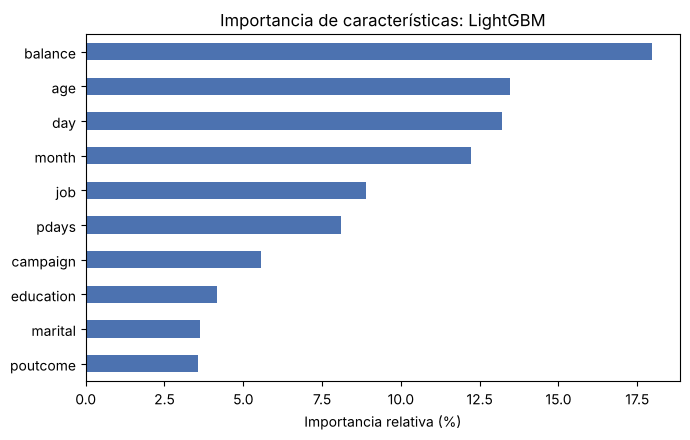

In [10]:
# Importancia de características del mejor modelo
paso_final = mejor_modelo.named_steps['modelo']
if hasattr(paso_final, 'feature_importances_'):
    modelo_importancias, nombre_importancias = mejor_modelo, mejor_nombre
else:
    modelo_importancias, nombre_importancias = optimizados['Random Forest'], 'Random Forest'

columnas_codificadas = modelo_importancias.named_steps['preprocesamiento'].get_feature_names_out()
valores = modelo_importancias.named_steps['modelo'].feature_importances_

# Cada variable categórica se expandió en varias columnas con one-hot; se suman para leer la
# importancia de la variable original
variable_origen = []
for columna in columnas_codificadas:
    limpia = columna.split('__', 1)[1]
    variable_origen.append(
        next((v for v in X.columns if limpia == v or limpia.startswith(v + '_')), limpia))

ranking = pd.Series(valores, index=variable_origen).groupby(level=0).sum()
ranking = (100 * ranking / ranking.sum()).sort_values(ascending=False)

print(f'Importancia de características: {nombre_importancias}')
for variable, porcentaje in ranking.head(10).items():
    print(f"   La importancia de '{variable}' es {porcentaje:.2f}%")

ranking.head(10).sort_values().plot(kind='barh', color='#4C72B0')
plt.xlabel('Importancia relativa (%)')
plt.title(f'Importancia de características: {nombre_importancias}')
plt.tight_layout()
plt.show()

## 6. Interpretación y recomendaciones de negocio

### ¿Qué modelo presenta mejor desempeño y por qué?

LightGBM optimizado es el mejor según el criterio declarado, con F1 de 0,3988, recall de 50 %,
precision de 33,2 %, ROC-AUC de 0,7325 y accuracy de 0,8267. Random Forest queda muy cerca, con F1
de 0,3599, y de hecho lo supera en las dos métricas de ordenamiento: ROC-AUC de 0,7402 y average
precision de 0,3398. El SVM RBF logra el recall más alto, 52,3 %, pero con la precision más baja del
grupo, 27,2 %. KNN queda muy por detrás, con F1 de 0,1350.

El resultado es coherente con la naturaleza del problema: el boosting corrige errores de forma
incremental y aprovecha bien las variables numéricas y categóricas mezcladas de este conjunto. La
línea base, en cambio, obtiene el accuracy más alto de la tabla, 0,8851, con recall de cero, lo que
muestra por qué el accuracy no puede ser el criterio de selección.

Con 1131 observaciones de prueba y solo 130 contratos, la diferencia entre LightGBM y Random Forest
es pequeña frente a la variabilidad esperable y otra semilla podría intercambiarlos. Si se prioriza
el ordenamiento de clientes por encima de la decisión a umbral fijo, Random Forest es igual de
defendible.

### ¿Qué métrica resulta más importante para el problema de negocio seleccionado?

Las métricas de ordenamiento, average precision y ROC-AUC, junto con el recall alcanzable dentro de
la capacidad de llamadas disponible. El banco no necesita una etiqueta por cliente sino una lista
priorizada, y esas métricas no dependen del umbral. El F1 se usó como criterio de búsqueda por su
equilibrio entre precision y recall, pero no es la métrica con la que se opera la campaña.

El accuracy queda descartado por el desbalance. Entre precision y recall la prioridad depende del
costo relativo: una llamada perdida cuesta el margen de un depósito no colocado, mientras una
llamada de más cuesta unos minutos de agente, así que conviene inclinarse al recall siempre que la
capacidad operativa lo permita.

### ¿Qué implicancias tiene el resultado para la toma de decisiones?

El aporte del modelo es la priorización, y su magnitud se puede medir. Llamando a los 100 clientes
mejor rankeados del conjunto de prueba se consiguen 40 contratos, una tasa de éxito de 40 % frente
al 11,5 % que daría llamar al azar, y se captura el 30,8 % de todos los contratos posibles. Con 300
llamadas se llega a 76 contratos, el 58,5 % del total posible, con un rendimiento 2,2 veces superior
al azar. La misma capacidad de llamadas produce bastante más colocación.

El análisis de umbral deja un hallazgo que conviene subrayar. Con los supuestos declarados el
beneficio estimado es casi plano entre los umbrales 0,05 y 0,30, con un máximo en 0,15 que
implicaría 922 llamadas sobre 1131 clientes. La razón es la asimetría de los supuestos: cuando el
margen equivale a unas diecinueve veces el costo de la llamada, el óptimo matemático es llamar a
casi todos. La lectura correcta no es llamar a todos, sino que el umbral debe fijarse por la
capacidad real del centro de contacto y no por el óptimo del modelo, que sirve para ordenar la cola
y no para recortarla. El conjunto de datos tampoco mide el desgaste de contactar en exceso a un
cliente, que es un costo real ausente de este cálculo.

### ¿Qué recomendación inicial realizarías al negocio?

Pilotear antes de desplegar. La propuesta es usar LightGBM para priorizar las primeras 100 a 300
llamadas de la próxima campaña, manteniendo un grupo de comparación que siga el procedimiento
actual, y medir la tasa de contratación por llamada en cada grupo. Solo con esos datos tiene sentido
estimar un retorno, porque las cifras de beneficio de la sección anterior son escenarios bajo
supuestos.

Tres condiciones acompañan la recomendación. El modelo se usa para ordenar contactos y no para negar
un producto. Antes de institucionalizar la priorización hay que revisar cómo se reparten las
llamadas por segmento, por el riesgo de variables proxy. Y conviene aprovechar lo que muestra la
importancia de características: el modelo se apoya sobre todo en el perfil financiero del cliente,
con `balance` cerca del 18 %, y en el momento del contacto, donde `day` y `month` suman alrededor de
una cuarta parte, lo que sugiere que cuándo se llama pesa casi tanto como a quién se llama y que el
calendario de la campaña debería planificarse junto con la lista de prioridad. En cambio `poutcome`
aparece con 3,6 %, lo que se explica porque 3705 de los 4521 registros no tienen historial previo,
así que mejorar ese registro es una inversión de bajo costo que hoy el modelo no puede explotar.

Cabe una advertencia de lectura: `feature_importances_` en LightGBM cuenta cortes del árbol, de modo
que favorece a las variables continuas con muchos valores posibles. Indica qué mira el modelo, no el
efecto de intervenir sobre esas variables.

### ¿Qué limitaciones presenta el análisis y qué información adicional sería útil?

El desempeño es modesto en términos absolutos, con ROC-AUC de 0,73 y precision de 33 % al umbral por
defecto. Parte de esa limitación es deliberada, porque se eliminó `duration`, que es el predictor más
fuerte del conjunto pero no está disponible al momento de decidir a quién llamar.

La partición es aleatoria estratificada y no temporal, mientras `day` y `month` concentran cerca de
una cuarta parte de la importancia, lo que apunta a un componente estacional; entrenar con períodos
previos y evaluar en períodos posteriores sería más realista. El conjunto corresponde a campañas
históricas de un banco europeo y no al banco que tomaría la decisión, de modo que la transferencia a
otro mercado o segmento no está garantizada. Con 130 contratos en prueba las métricas tienen
intervalos amplios y las comparaciones finas no son concluyentes. Las probabilidades no fueron
calibradas, así que sirven para ordenar pero deberían calibrarse antes de usarse en cualquier
cálculo monetario. Y el modelo describe asociación y no causalidad: que un cliente con cierto
historial tenga mayor probabilidad de contratar no implica que la llamada sea la causa del contrato.

La información adicional que más aportaría es el costo real por llamada y el margen real por
producto, para reemplazar los supuestos; la capacidad semanal del centro de contacto, que es la
restricción que de verdad fija el umbral; la fecha completa del contacto, para validación temporal;
el resultado de campañas recientes y no solo de la anterior; y señales de relación con el banco como
antigüedad, productos contratados o reclamos registrados.

Como mejoras futuras: calibrar las probabilidades, fijar el umbral por capacidad, incorporar
validación temporal, probar XGBoost como alternativa de boosting y evaluar el desempeño por
subgrupos antes de cualquier despliegue.